# Data preprocessment

In [144]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
import librosa
import librosa.display
import numpy as np
import soundfile as sf
import pathlib
from sklearn.model_selection import GroupShuffleSplit
from scipy.signal import butter, sosfiltfilt
sns.set_theme(style="whitegrid")

In [145]:
# Data and paths
df = pd.read_csv(r"C:\Users\franc\Desktop\AC2\data\training_data.csv")
files_path = pathlib.Path(r"C:\Users\franc\Desktop\AC2\data\training_data")
extension = ".wav"

# Put all the .wav files in a separate folder
destination = pathlib.Path(r"C:\Users\franc\Desktop\AC2\data\audio")
destination.mkdir(parents=True, exist_ok=True)
moved = 0
for p in files_path.rglob("*"):
    if p.is_file() and p.suffix.lower() == ".wav":
        p.rename(destination / p.name)
        moved += 1
audio_files = [p for p in destination.rglob("*") if p.is_file() and p.suffix.lower() == extension]

In [146]:

drop = []
for col in df.columns:
    if col not in ["Patient ID", "Murmur", "Recording locations:", "Murmur locations"]:
        drop.append(col)
df = df.drop(columns=drop)

In [147]:
df["Patient ID"].nunique() # no duplicated patients
# Adding the audio files' paths to the dataframe
audio_files_by_patient = {}
for audio_file in audio_files:
    patient_id = audio_file.stem.split("_", 1)[0]
    audio_files_by_patient.setdefault(patient_id, []).append(str(audio_file))

patient_ids = df["Patient ID"].astype(str)
missing_patient_ids = sorted(set(patient_ids) - audio_files_by_patient.keys())
if missing_patient_ids:
    raise FileNotFoundError(f"No audio files found for patient IDs: {missing_patient_ids}")

df["Audio Path"] = patient_ids.map(audio_files_by_patient)
df = df.explode("Audio Path", ignore_index=True)
df.head()

,Patient ID,Recording locations:,Murmur,Murmur locations,Audio Path
0,2530,AV+PV+TV+MV,Absent,NaN,C:\Users\franc\Desktop\AC2\data\audio\2530_AV.wav
1,2530,AV+PV+TV+MV,Absent,NaN,C:\Users\franc\Desktop\AC2\data\audio\2530_MV.wav
2,2530,AV+PV+TV+MV,Absent,NaN,C:\Users\franc\Desktop\AC2\data\audio\2530_PV.wav
3,2530,AV+PV+TV+MV,Absent,NaN,C:\Users\franc\Desktop\AC2\data\audio\2530_TV.wav
4,9979,AV+PV+TV+MV,Present,AV+MV+PV+TV,C:\Users\franc\Desktop\AC2\data\audio\9979_AV.wav


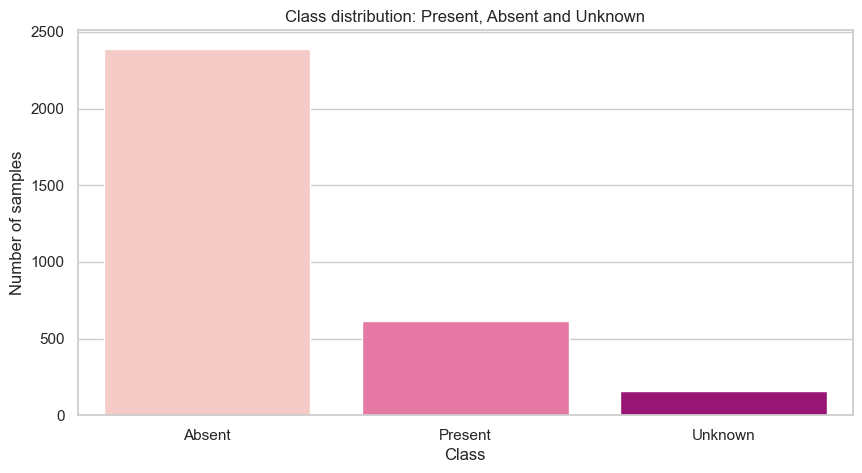

In [148]:
# Verifying the label distribution
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="Murmur", order=sorted(df["Murmur"].unique()), palette="RdPu", hue="Murmur")
plt.title("Class distribution: Present, Absent and Unknown")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.show()

## Uniformizing inputs

Firstly, we perform validation steps for all data avaliable, needed for all future implemented architectures.

### 1. Validating the audio files

In [149]:
path = pathlib.Path(r"C:\Users\franc\Desktop\AC2\data\audio")
reports = []

for file in path.rglob("*"):
    data, sr = sf.read(file, dtype="float32", always_2d=True)

    report = {
        "file_name": file.name,
        "sample_rate": sr,
        "n_samples": data.shape[0], # if zero - header but no audio
        "duration_s": data.shape[0] / sr,
        "is_empty": data.shape[0] == 0,
        "is_all_zero": bool(np.all(data == 0)),
        "has_nan": bool(np.isnan(data).any()),
        "has_inf": bool(np.isinf(data).any()),
    }

    if report["has_nan"] or report["has_inf"]:
        data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)

    peak = float(np.max(np.abs(data))) if data.size else 0.0
    rms = float(np.sqrt(np.mean(data**2))) if data.size else 0.0
    report["peak"] = peak
    report["rms_db"] = 20 * np.log10(rms) if rms > 0 else -np.inf
    report["peak_db"] = 20 * np.log10(peak) if peak > 0 else -np.inf
    report["out_of_range"] = peak > 1.0

    reports.append(report)

df_report = pd.DataFrame(reports)
df_report.head()

,file_name,sample_rate,n_samples,duration_s,is_empty,is_all_zero,has_nan,has_inf,peak,rms_db,peak_db,out_of_range
0,13918_AV.wav,4000,41152,10.288,False,False,False,False,1.000000,-25.770067,0.000000,False
1,13918_MV.wav,4000,115136,28.784,False,False,False,False,1.000000,-29.029928,0.000000,False
2,13918_PV.wav,4000,37568,9.392,False,False,False,False,1.000000,-27.122108,0.000000,False
3,13918_TV.wav,4000,26368,6.592,False,False,False,False,1.000000,-26.208914,0.000000,False
4,14241_AV.wav,4000,81920,20.480,False,False,False,False,0.999969,-28.275844,-0.000265,False


There aren't any audio files with suspecting values or no duration. Besisdes that, the sample rate across all of them is of 4000 Hz. Therefore, we don't need to standardize the frequency.

C:\Users\franc\AppData\Local\Temp\ipykernel_4316\1468946307.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df_report, x="duration_s", palette="RdPu")


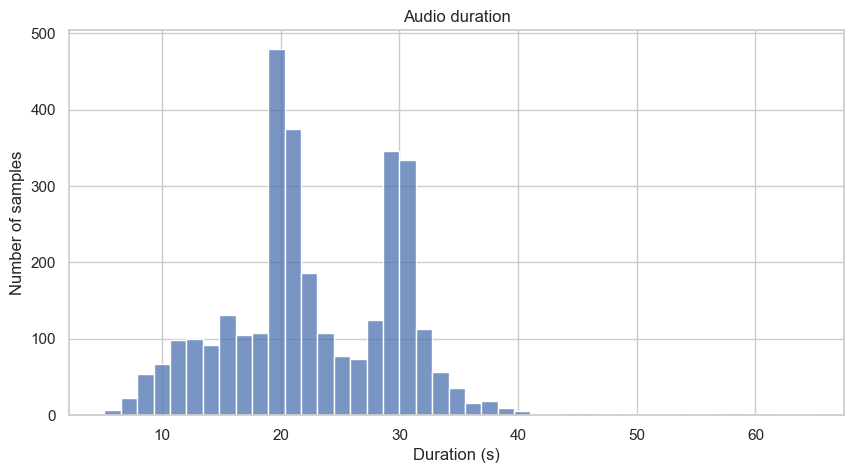

In [150]:
# Verifying the distribution of the duration of the records
plt.figure(figsize=(10, 5))
sns.histplot(data=df_report, x="duration_s", palette="RdPu")
plt.title("Audio duration")
plt.xlabel("Duration (s)")
plt.ylabel("Number of samples")
plt.show()

### 2. Split patients into train, validation and test sets

In [151]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)

train_idx, temp_idx = next(splitter.split(df, groups=df["Patient ID"]))
train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# Divide the remaining 20% into validation and test
splitter = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)

val_idx, test_idx = next(splitter.split(temp_df, groups=temp_df["Patient ID"]))
val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

train_patients = set(train_df["Patient ID"])
val_patients = set(val_df["Patient ID"])
test_patients = set(test_df["Patient ID"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

We'll create 3 different datasets, each one processed differently to fit the desired input for each architecture. We will uniformize the recording's duration with **fixed-length windows**, which consists of splitting long recordings into shorter segments. This preserves more of the original recording and creates multiple training examples.

In [152]:
# Split an audio recording into non-overlapping 5 second length windows.
# The final incomplete window is zero-padded, only of its durration is above 2.5s
# If it is shorter than that, we drop the last window

def split_audio_into_windows(audio, sr, window_duration=5):
    window_size = sr * window_duration
    windows = []
    valid_lengths = []
    for start in range(0, len(audio), window_size):
        window = audio[start:start + window_size]
        valid_length = len(window)
        # Pad the final incomplete window with zeros
        if valid_length < 2.5 * 4000:
            break
        if valid_length < window_size:
            window = np.pad(window,(0, window_size - valid_length),mode="constant")
        windows.append(window)
        valid_lengths.append(valid_length)
    return np.array(windows), valid_lengths

### 3. Dealing with noisy data

Firstly, we filter the whole signal first, then drop only the windows that are still unusable after filtering.

Heart sounds and murmurs sit roughly between 25 and 400 Hz: energy outside that band is mostly noise.

In [153]:

def normalize_amplitude(audio):
    peak = np.max(np.abs(audio))
    if peak == 0:
        return audio
    return audio / peak

def clean_noise(audio):
    sos = butter(4, [25, 400], btype="band", fs=4000, output="sos")
    audio = sosfiltfilt(sos, audio)          # band-pass
    return normalize_amplitude(audio)

# Very low RMS - silent or flat
# Peak-to-RMS ratio or high-percentile amplitude - loud burst
# Low fraction of energy in 25-400 Hz - broadband noise

def window_quality(w, raw_w, sr=4000):
    rms = np.sqrt(np.mean(w**2))                               # loudness
    crest = np.max(np.abs(w)) / (rms + 1e-12)                  # high = isolated spikes
    spec = np.abs(np.fft.rfft(raw_w))**2
    freqs = np.fft.rfftfreq(len(raw_w), 1/sr)
    band_ratio = spec[(freqs >= 25) & (freqs <= 400)].sum() / (spec.sum() + 1e-12)  # low = mostly out-of-band noise
    return {"rms": rms, "crest": crest, "band_ratio": band_ratio}

For all recordings, we follow this pipeline:

1. Clean the audio throughoutly and normalize the amplitude, by dividing by the maximum absolute amplitude, with a small numerical safeguard against silence.

2. Divide the waveform into 5-second windows. Initially, use non-overlapping windows to keep the number of training examples manageable.

3. If the final window is shorter than 5 seconds, pad it with zeros.

In [154]:
splits = [("train", train_df), ("val", val_df), ("test", test_df)]
win_dir = pathlib.Path("./processed_data/windows")
win_dir.mkdir(parents=True, exist_ok=True)

for split, split_df in splits:
    X, meta = [], []
    for _, row in split_df.iterrows():
        audio_path = row["Audio Path"]
        audio, sr = sf.read(audio_path, dtype="float32")
        recording_id = os.path.splitext(os.path.basename(audio_path))[0]
        windows, valid_lengths = split_audio_into_windows(audio=clean_noise(audio), sr=sr)
        raw_windows, _ = split_audio_into_windows(audio=audio, sr=sr)   # same windows, before filtering
        assert len(windows) == len(raw_windows)
        for window_id, (window, raw_window, valid_length) in enumerate(zip(windows, raw_windows, valid_lengths)):
            quality = window_quality(window[:valid_length], raw_window[:valid_length], sr=sr)
            X.append(window)
            meta.append({
                "Patient ID": row["Patient ID"],
                "Recording ID": recording_id,
                "Window ID": window_id,
                "Valid Length": valid_length,
                "Murmur": row["Murmur"],
                **quality,
            })

    X = np.stack(X).astype("float32")[..., None]
    meta_df = pd.DataFrame(meta)
    np.save(win_dir / f"X_{split}_windows.npy", X)
    meta_df.to_csv(win_dir / f"meta_{split}_windows.csv", index=False)
    print(f"{split}: X={X.shape}, windows={len(meta_df)}")

train: X=(11679, 20000, 1), windows=11679
val: X=(1379, 20000, 1), windows=1379
test: X=(1358, 20000, 1), windows=1358


In [155]:
meta = {s: pd.read_csv(win_dir / f"meta_{s}_windows.csv") for s in ["train", "val", "test"]}

tr = meta["train"]
thr = {"rms_lo": np.percentile(tr["rms"], 1),
       "crest_hi": np.percentile(tr["crest"], 99),
       "band_lo": np.percentile(tr["band_ratio"], 1)}
print({k: round(float(v), 4) for k, v in thr.items()})

for s, m in meta.items():
    m["noisy"] = (m["rms"] < thr["rms_lo"]) | (m["crest"] > thr["crest_hi"]) | (m["band_ratio"] < thr["band_lo"])
    m["keep"] = ~m["noisy"]
    m.to_csv(win_dir / f"meta_{s}_windows.csv", index=False)
    print(f"\n{s}: {len(m)} windows | flagged {int(m['noisy'].sum())} | kept {int(m['keep'].sum())}")
    print(pd.crosstab(m["Murmur"], m["noisy"], normalize="index").round(3).rename(columns={False: "kept", True: "flagged"}))

{'rms_lo': 0.0046, 'crest_hi': 39.3133, 'band_lo': 0.1075}

train: 11679 windows | flagged 341 | kept 11338
noisy     kept  flagged
Murmur                 
Absent   0.969    0.031
Present  0.985    0.015
Unknown  0.947    0.053

val: 1379 windows | flagged 26 | kept 1353
noisy     kept  flagged
Murmur                 
Absent   0.978    0.022
Present  0.993    0.007
Unknown  0.974    0.026

test: 1358 windows | flagged 39 | kept 1319
noisy     kept  flagged
Murmur                 
Absent   0.972    0.028
Present  0.978    0.022
Unknown  0.944    0.056


### 1D CNN using raw audio waveforms

In [156]:
label_map = {"Absent": 0, "Present": 1, "Unknown": 2}

def load_kept(split):
    """Windows that passed the noise filter: identical rows for every architecture."""
    X = np.load(win_dir / f"X_{split}_windows.npy", mmap_mode="r")
    m = pd.read_csv(win_dir / f"meta_{split}_windows.csv")
    keep = m["keep"].to_numpy()
    return np.asarray(X[keep]), m[keep].reset_index(drop=True)

out_dir = pathlib.Path("./processed_data/cnn_1d")
out_dir.mkdir(parents=True, exist_ok=True)

for split in ["train", "val", "test"]:
    X, meta_df = load_kept(split)
    y = meta_df["Murmur"].map(label_map).to_numpy()
    groups = meta_df["Patient ID"].to_numpy()

    np.save(out_dir / f"X_{split}_1d.npy", X)
    np.save(out_dir / f"y_{split}_1d.npy", y)
    np.save(out_dir / f"groups_{split}_1d.npy", groups)
    meta_df.to_csv(out_dir / f"meta_{split}_1d.csv", index=False)
    print(f"{split}: X={X.shape}, y={y.shape}")

train: X=(11338, 20000, 1), y=(11338,)
val: X=(1353, 20000, 1), y=(1353,)
test: X=(1319, 20000, 1), y=(1319,)


In [157]:
splits = ["train", "val", "test"]
dfs = {
    s: {
        "X": np.load(f"./processed_data/cnn_1d/X_{s}_1d.npy"),
        "meta": pd.read_csv(f"./processed_data/cnn_1d/meta_{s}_1d.csv"),
    }
    for s in splits
}

for s, d in dfs.items():
    X, meta = d["X"], d["meta"]
    print(s, len(X), meta["Patient ID"].nunique(), "patients")
    print(meta["Murmur"].value_counts(normalize=True).round(3).to_dict())
    print("audio shape:", X[0].shape, "| NaN:", np.isnan(X).any())

train 11338 753 patients
{'Absent': 0.762, 'Present': 0.194, 'Unknown': 0.044}
audio shape: (20000, 1) | NaN: False
val 1353 94 patients
{'Absent': 0.737, 'Present': 0.208, 'Unknown': 0.055}
audio shape: (20000, 1) | NaN: False
test 1319 95 patients
{'Absent': 0.768, 'Present': 0.168, 'Unknown': 0.064}
audio shape: (20000, 1) | NaN: False


### 2D CNN using log-Mel spectograms

A **log-Mel spectrogram** is a time-frequency "image" of the audio. Each 5 s window goes through three steps:

1. **STFT**: slide a short window (`n_fft` samples) along the signal in steps of `hop_length` samples and take an FFT in each one. This gives the energy at each frequency over time.

2. **Mel filterbank**: group the linear FFT bins into `n_mels` overlapping triangular bands, spaced on the mel scale (narrow at low frequencies, wide at high ones). This compresses the frequency axis and emphasizes the low frequencies where heart sounds live.

3. **Log**: convert power to a log (dB) scale. Raw power spans many orders of magnitude (S1/S2 are far louder than a murmur), and the log makes quiet and loud structure comparable. A small floor (`amin`) avoids `log(0)`.

The result is a 2D array of shape `(n_mels, time_frames)`, which the CNN treats as a one-channel image: frequency on the vertical axis, time on the horizontal axis.

**Parameters (identical for every window):** `n_fft=256` (64 ms), `hop=128` (32 ms), `n_mels=64`, 0-2000 Hz. At 4000 Hz the Nyquist frequency is 2000 Hz, so this covers the full band. Each 5 s window (20000 samples) gives `1 + 20000 // 128 = 157` frames, so each input is `(64, 157, 1)`.

In [158]:
SR = 4000
WINDOW_S = 5
N_FFT = 256
HOP = 128
N_MELS = 64
FMIN, FMAX = 0, 2000
AMIN = 1e-10
N_FRAMES = 1 + (SR * WINDOW_S) // HOP   # 157

# The Librosa library automatically does the conversion for log-Mel spectograms
def window_to_logmel(window):
    """5 s waveform window -> log-Mel spectrogram (N_MELS, N_FRAMES) in dB."""
    mel = librosa.feature.melspectrogram(
        y=window, sr=SR, n_fft=N_FFT, hop_length=HOP,
        n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0)
    return librosa.power_to_db(mel, ref=1.0, amin=AMIN, top_db=None).astype("float32")

print(f"Frequency resolution: {SR / N_FFT:.1f} Hz/bin | window: {1000*N_FFT/SR:.0f} ms | hop: {1000*HOP/SR:.0f} ms")
print(f"Expected input shape: ({N_MELS}, {N_FRAMES}, 1)")

Frequency resolution: 15.6 Hz/bin | window: 64 ms | hop: 32 ms
Expected input shape: (64, 157, 1)


The four panels show each stage for the first 5s of one recording: the waveform, the linear-frequency STFT (dB), the Mel spectrogram in raw power, and the final log-Mel. The raw-power panel is mostly dark, which is why the log step is needed.

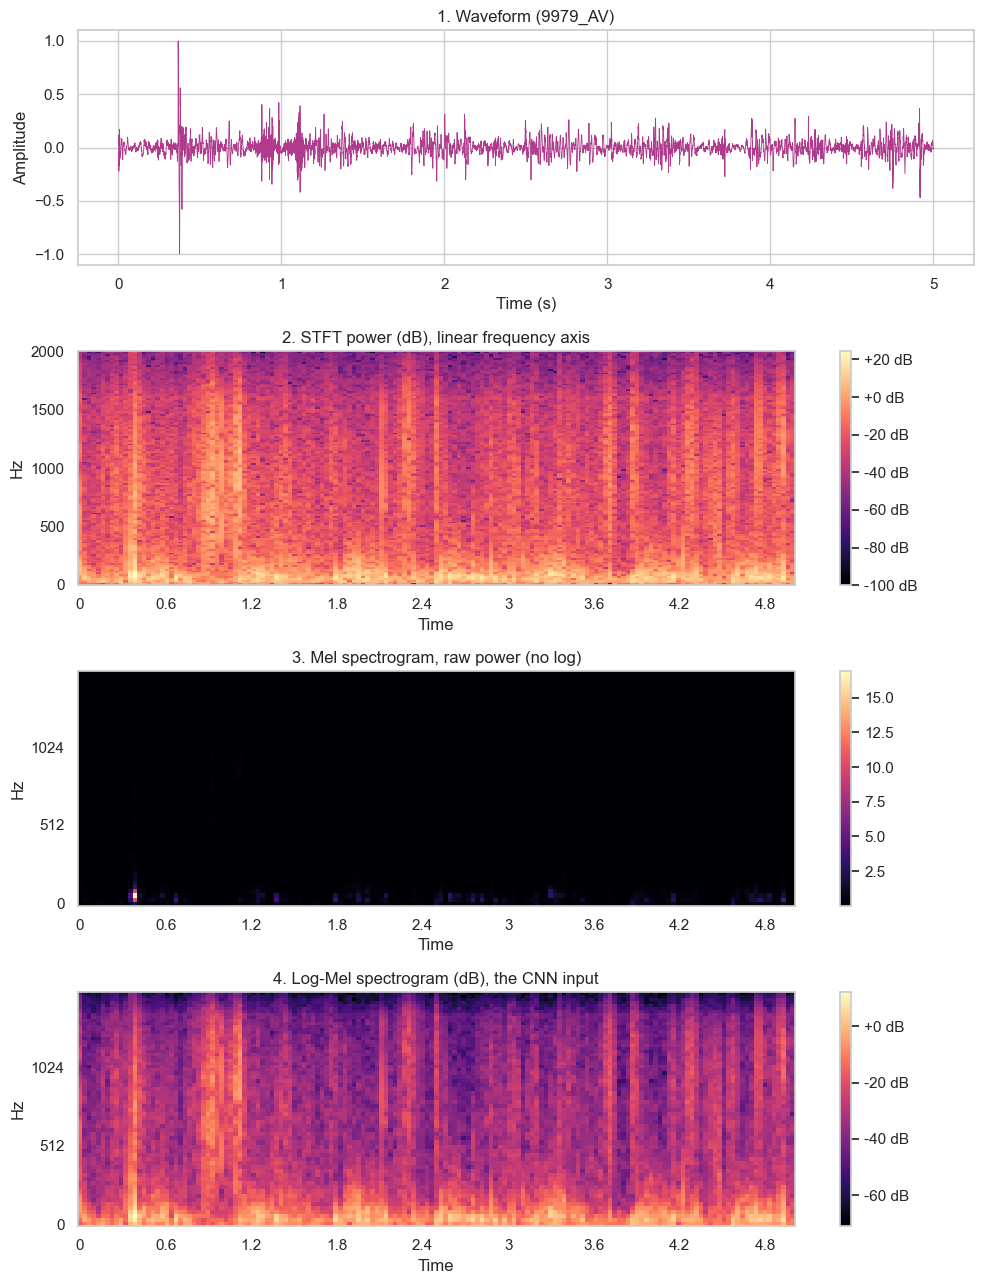

In [159]:
def first_window(df_, murmur):
    """First 5 s window of the first recording with the given label and auscultation location."""
    sub = df_[(df_["Murmur"] == murmur)]
    row = sub.iloc[0]
    audio, sr = sf.read(row["Audio Path"], dtype="float32")
    assert sr == SR
    windows, _ = split_audio_into_windows(normalize_amplitude(audio), sr, WINDOW_S)
    return windows[0], pathlib.Path(row["Audio Path"]).stem

w, name = first_window(train_df, "Present")
t = np.arange(len(w)) / SR

stft_db = librosa.power_to_db(np.abs(librosa.stft(w, n_fft=N_FFT, hop_length=HOP))**2,
                              ref=1.0, amin=AMIN, top_db=None)
mel_power = librosa.feature.melspectrogram(y=w, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                           n_mels=N_MELS, fmin=FMIN, fmax=FMAX)
logmel = window_to_logmel(w)

fig, ax = plt.subplots(4, 1, figsize=(10, 13))
ax[0].plot(t, w, lw=0.6, color="#b03a8c")
ax[0].set(title=f"1. Waveform ({name})", xlabel="Time (s)", ylabel="Amplitude")

im = librosa.display.specshow(stft_db, sr=SR, hop_length=HOP, x_axis="time", y_axis="linear", ax=ax[1], cmap="magma")
ax[1].set_title("2. STFT power (dB), linear frequency axis"); fig.colorbar(im, ax=ax[1], format="%+.0f dB")

im = librosa.display.specshow(mel_power, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
                              fmin=FMIN, fmax=FMAX, ax=ax[2], cmap="magma")
ax[2].set_title("3. Mel spectrogram, raw power (no log)"); fig.colorbar(im, ax=ax[2])

im = librosa.display.specshow(logmel, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
                              fmin=FMIN, fmax=FMAX, ax=ax[3], cmap="magma")
ax[3].set_title("4. Log-Mel spectrogram (dB), the CNN input"); fig.colorbar(im, ax=ax[3], format="%+.0f dB")

plt.tight_layout(); plt.show()

In [160]:
out_dir = pathlib.Path("./processed_data/cnn_2d")
out_dir.mkdir(parents=True, exist_ok=True)

for split in ["train", "val", "test"]:
    Xw, meta_df = load_kept(split)
    X = np.stack([window_to_logmel(w[:, 0]) for w in Xw]).astype("float32")[..., None]
    y = meta_df["Murmur"].map(label_map).to_numpy()
    groups = meta_df["Patient ID"].to_numpy()

    # same windows as the 1D dataset
    m1 = pd.read_csv(f"./processed_data/cnn_1d/meta_{split}_1d.csv")
    assert m1[["Recording ID", "Window ID"]].equals(meta_df[["Recording ID", "Window ID"]])

    np.save(out_dir / f"X_{split}_2d.npy", X)
    np.save(out_dir / f"y_{split}_2d.npy", y)
    np.save(out_dir / f"groups_{split}_2d.npy", groups)
    meta_df.to_csv(out_dir / f"meta_{split}_2d.csv", index=False)
    print(f"{split}: X={X.shape}, y={y.shape}")

train: X=(11338, 64, 157, 1), y=(11338,)
val: X=(1353, 64, 157, 1), y=(1353,)
test: X=(1319, 64, 157, 1), y=(1319,)


### RNN
We only need to correct the tensor dimensions for the RNN, since we did the log-Mel conversion in the previous section.

In [162]:

out_dir = pathlib.Path("./processed_data/rnn")

for split in ["train", "val", "test"]:
    Xw, meta_df = load_kept(split)

    # Initial shape: (n_windows, 64, 157)
    X = np.stack([window_to_logmel(w[:, 0]) for w in Xw]).astype("float32")

    # Transpose to (n_windows, 157, 64)
    X = np.transpose(X, (0, 2, 1))

    y = meta_df["Murmur"].map(label_map).to_numpy()
    groups = meta_df["Patient ID"].to_numpy()

    # Verify that the same windows are used across architectures
    m1 = pd.read_csv(f"./processed_data/cnn_1d/meta_{split}_1d.csv")
    assert m1[["Recording ID", "Window ID"]].equals(meta_df[["Recording ID", "Window ID"]])

    np.save(out_dir / f"X_{split}_rnn.npy", X)
    np.save(out_dir / f"y_{split}_rnn.npy", y)
    np.save(out_dir / f"groups_{split}_rnn.npy", groups)

    meta_df.to_csv(out_dir / f"meta_{split}_rnn.csv",index=False)

    print(f"{split}: X={X.shape}, y={y.shape}")


train: X=(11338, 157, 64), y=(11338,)
val: X=(1353, 157, 64), y=(1353,)
test: X=(1319, 157, 64), y=(1319,)


In [ ]:
# TODO: Check the correctness of all inputs (in terms of shape, mainly)
# TODO: Verify if there are patients with missing recording on certain locations 